# Pass 08

## Problem Definition


Business problem: estimate a house's sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find the float column and make it into a
floats_columns = house_df.select_dtypes(include='float64').columns.tolist()
floats_columns

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [5]:
target_floats= ['SalePrice'] + floats_columns

In [6]:
house_df_target_floats= house_df[target_floats]

In [7]:
# Columns data types
house_df_target_floats.dtypes.sort_values()


,0
SalePrice,int64
Lot Frontage,float64
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64
Garage Yr Blt,float64


In [8]:
# look at first and last few rows
house_df_target_floats.head()


,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0


In [9]:
# look at the last few rows
house_df_target_floats.tail()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0
2636,225000,41.0,0.0,870.0,0.0,167.0,1037.0,0.0,0.0,1999.0,2.0,400.0


In [10]:
# look at shape and size

print(house_df_target_floats.shape)
print(house_df_target_floats.size)


(2637, 12)
31644


In [11]:
# display meta data (info)
house_df_target_floats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SalePrice       2637 non-null   int64  
 1   Lot Frontage    2188 non-null   float64
 2   Mas Vnr Area    2614 non-null   float64
 3   BsmtFin SF 1    2636 non-null   float64
 4   BsmtFin SF 2    2636 non-null   float64
 5   Bsmt Unf SF     2636 non-null   float64
 6   Total Bsmt SF   2636 non-null   float64
 7   Bsmt Full Bath  2635 non-null   float64
 8   Bsmt Half Bath  2635 non-null   float64
 9   Garage Yr Blt   2490 non-null   float64
 10  Garage Cars     2636 non-null   float64
 11  Garage Area     2636 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 247.3 KB


In [12]:
# display summary statistics
house_df_target_floats.describe()



,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
count,2637.000000,2188.000000,2614.000000,2636.000000,2636.000000,2636.000000,2636.000000,2635.000000,2635.000000,2490.000000,2636.000000,2636.000000
mean,179986.230186,69.166819,101.887911,438.441199,51.068665,555.669196,1045.179059,0.432258,0.058824,1978.185944,1.763278,470.968134
std,78309.251522,23.356779,179.578232,449.602326,172.521803,436.223188,429.686089,0.525239,0.240130,25.452647,0.760576,212.816905
min,12789.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1895.000000,0.000000,0.000000
25%,129500.000000,58.000000,0.000000,0.000000,0.000000,218.000000,792.000000,0.000000,0.000000,1961.000000,1.000000,324.750000
50%,160000.000000,68.000000,0.000000,368.000000,0.000000,464.500000,988.000000,0.000000,0.000000,1979.000000,2.000000,480.000000
75%,213000.000000,80.000000,164.000000,732.000000,0.000000,797.250000,1290.250000,1.000000,0.000000,2002.000000,2.000000,576.000000
max,745000.000000,313.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,3.000000,2.000000,2207.000000,5.000000,1488.000000


In [13]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [14]:
# look for nulls in target and features
house_df_target_floats.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
BsmtFin SF 1,1
Total Bsmt SF,1
BsmtFin SF 2,1
Garage Cars,1
Bsmt Unf SF,1


## Data Cleaning


### Backup 1

In [15]:
# make backup
house_df_target_floats_backup = house_df_target_floats.copy()

In [16]:
# restore from backup
house_df_target_floats = house_df_target_floats_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [17]:
# look for nulls in feature in percentage
house_df_target_floats.isnull().mean() * 100

,0
SalePrice,0.000000
Lot Frontage,17.026925
Mas Vnr Area,0.872203
BsmtFin SF 1,0.037922
BsmtFin SF 2,0.037922
Bsmt Unf SF,0.037922
Total Bsmt SF,0.037922
Bsmt Full Bath,0.075844
Bsmt Half Bath,0.075844
Garage Yr Blt,5.574516


### Impute

In [18]:
# Calculate the median
median_frontage = house_df_target_floats['Lot Frontage'].median()
median_garage_yr = house_df_target_floats['Garage Yr Blt'].median()

print(median_frontage)
print(median_garage_yr)

# Fill nulls with the median
house_df_target_floats['Lot Frontage']= house_df_target_floats['Lot Frontage'].fillna(median_frontage)
house_df_target_floats['Garage Yr Blt']= house_df_target_floats['Garage Yr Blt'].fillna(median_garage_yr)

#verify there are no nulls
house_df_target_floats.isnull().sum()


68.0
1979.0


,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,23
BsmtFin SF 1,1
BsmtFin SF 2,1
Bsmt Unf SF,1
Total Bsmt SF,1
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Yr Blt,0


In [19]:
print(house_df_target_floats['Lot Frontage'].median())
print(house_df_target_floats['Garage Yr Blt'].median())

68.0
1979.0


In [20]:
# find the columns with nulls using large number to find it easier
house_df_target_floats.isnull().sum() * 100000

,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,2300000
BsmtFin SF 1,100000
BsmtFin SF 2,100000
Bsmt Unf SF,100000
Total Bsmt SF,100000
Bsmt Full Bath,200000
Bsmt Half Bath,200000
Garage Yr Blt,0


In [21]:
# drop the nulls values in features
house_df_target_floats = house_df_target_floats.dropna(subset=['Mas Vnr Area',
'BsmtFin SF 1',
'BsmtFin SF 2',
'Bsmt Unf SF',
'Total Bsmt SF',
'Bsmt Full Bath',
'Garage Cars',
'Garage Area',
'Bsmt Half Bath'])

In [22]:
#check that null are removed from features
house_df_target_floats.isnull().sum()

,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Total Bsmt SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0
Garage Yr Blt,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

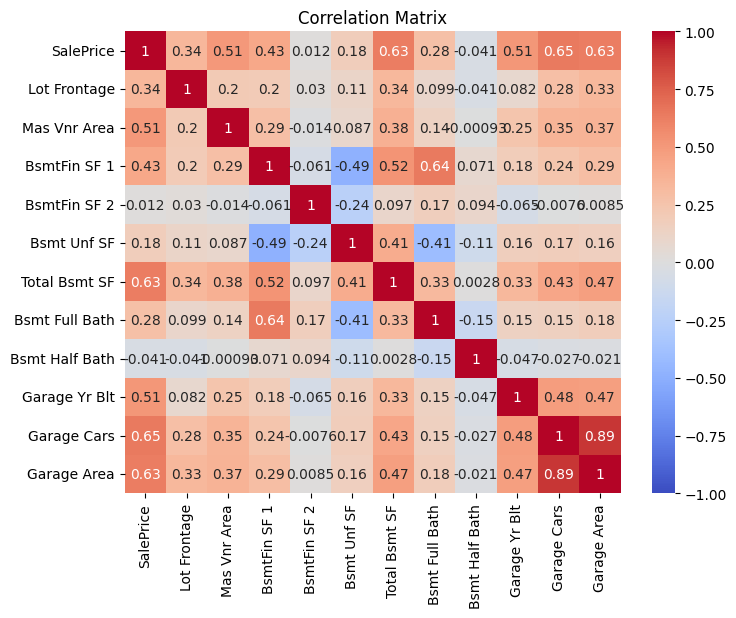

In [23]:
# Calcualte & display  correlation matrix, check if feature corelated with target
plt.figure(figsize=(8, 6))
sns.heatmap(house_df_target_floats.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

In [24]:
# Calculate a correlation matrix for features & features
features_df = house_df_target_floats.drop(columns=['SalePrice'])
features_corr = features_df.corr()

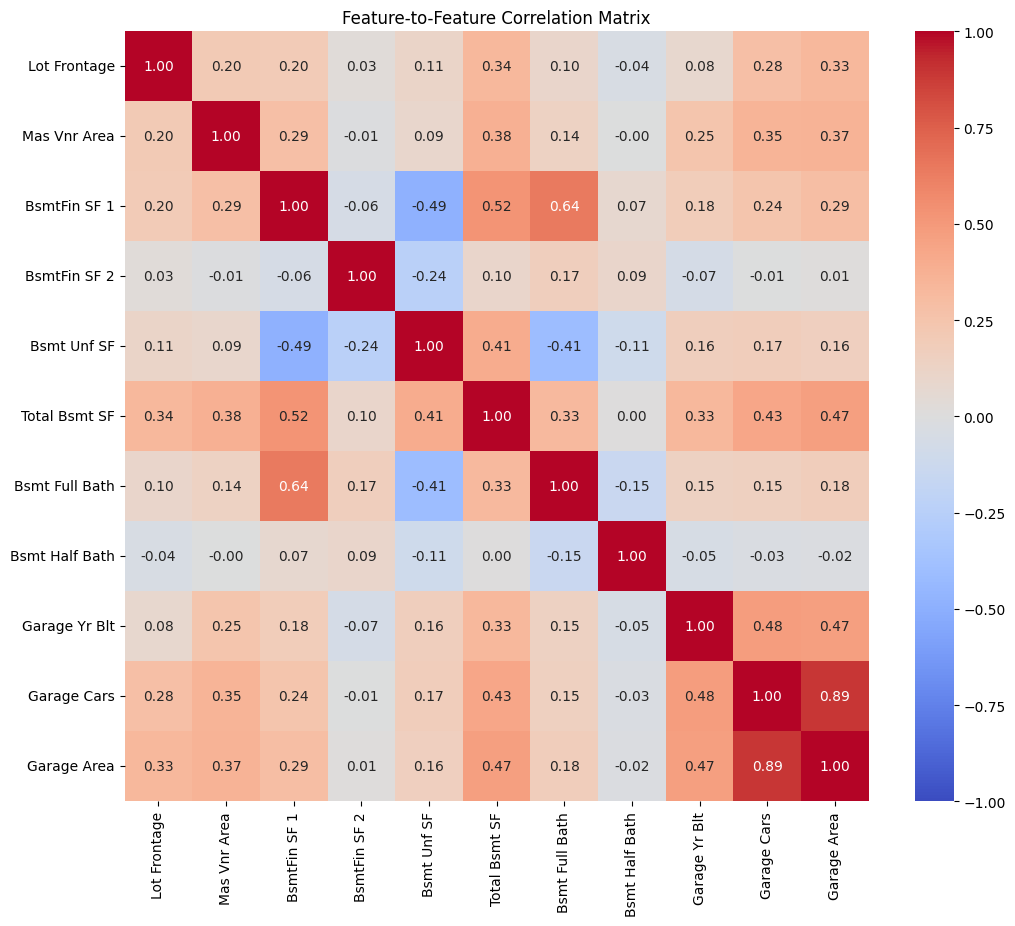

In [25]:
# Display the matrix, check if features are correlated with each other
plt.figure(figsize=(12, 10))      # bigger, since there are more columns
sns.heatmap(features_corr,
            annot=True,
            fmt='.2f',            # round numbers to 2 decimals so they fit
            cmap='coolwarm',
            center=0,
            vmin=-1, vmax=1)
plt.title('Feature-to-Feature Correlation Matrix')
plt.show()

#### Feature Selection

In [26]:
# Score each feature by how strongly it moves with SalePrice
corrs = house_df_target_floats.corr()['SalePrice'].abs().sort_values(ascending=False)
corrs

,SalePrice
SalePrice,1.000000
Garage Cars,0.646209
Garage Area,0.632404
Total Bsmt SF,0.631127
Garage Yr Blt,0.514283
Mas Vnr Area,0.506778
BsmtFin SF 1,0.428710
Lot Frontage,0.338531
Bsmt Full Bath,0.278135
Bsmt Unf SF,0.175068


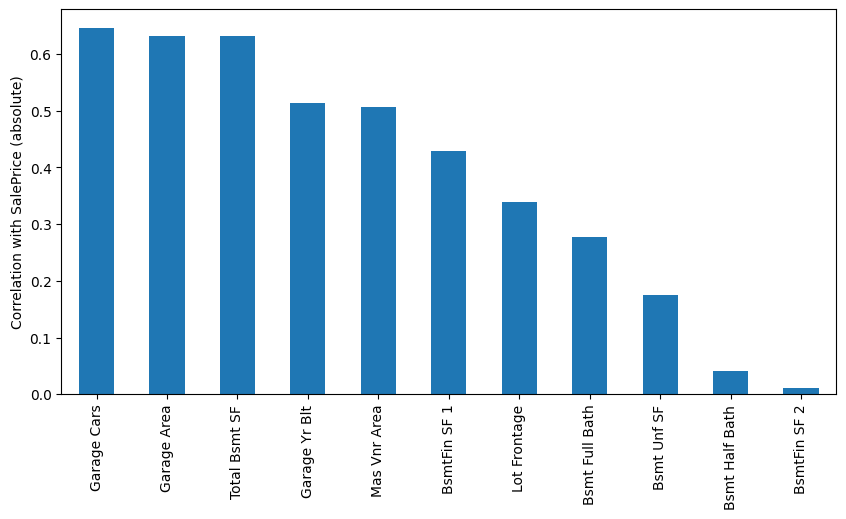

In [27]:
# Bar graph of the scores (drop SalePrice, since it always scores 1 with itself)
corrs.drop('SalePrice').plot(kind='bar', figsize=(10,5))
plt.ylabel('Correlation with SalePrice (absolute)');

In [28]:
# Pick the single strongest feature
best_feature = corrs.drop('SalePrice').index[0]
best_feature

'Garage Cars'

## Processing



### Fit & Assess model- Using linear Regression

In [29]:
# break data into training and testing sets
X = house_df_target_floats[[best_feature]]
y = house_df_target_floats['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [30]:
# Fit a linear model using sklearn
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

(model.intercept_, model.coef_)

(np.float64(64245.16039911394), array([64765.1878974]))

[(270000, np.float64(193775.53619392094)),
 (255000, np.float64(193775.53619392094)),
 (149900, np.float64(193775.53619392094)),
 (260000, np.float64(193775.53619392094)),
 (143750, np.float64(193775.53619392094)),
 (115000, np.float64(129010.34829651745)),
 (140000, np.float64(193775.53619392094)),
 (213750, np.float64(193775.53619392094)),
 (173000, np.float64(193775.53619392094)),
 (124500, np.float64(129010.34829651745))]

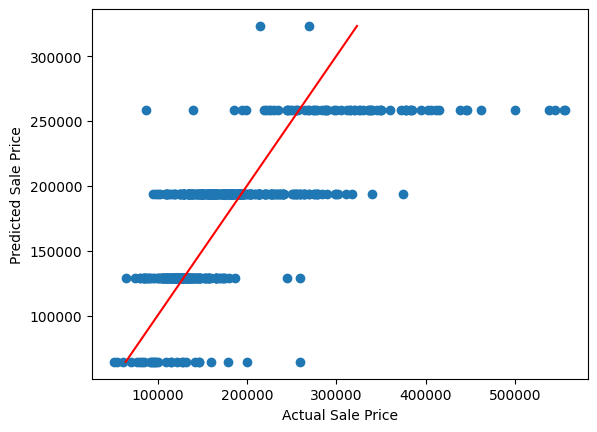

In [31]:
# See how well the model does compare to the test data

plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

list(zip(y_test, y_pred))[:10]

In [32]:
# RMS on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse} ")

#RMSE- shows the amount the model was wrong

RMSE: 58845.99329184402 


In [33]:
# Use cross validation to assess model performance
results = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=10)
cv_rmse = abs(results.mean())
print(f"CV RMSE: {cv_rmse}")

#Run validation multiple times compare to single cv number barely change
#the single sv lucky that how the model work

CV RMSE: 59541.65899758561


## Residual Analysis

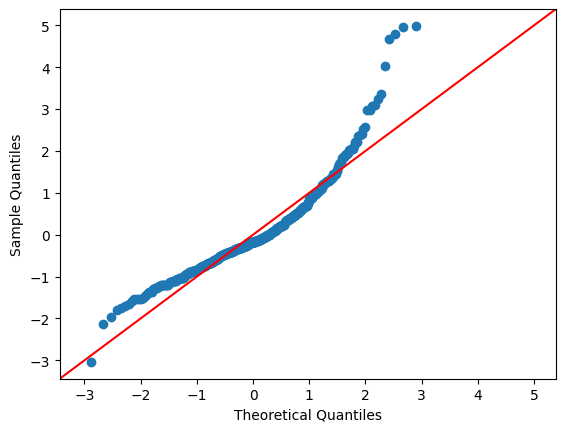

In [34]:
# QQ Plot - Checks if residuals(misses)are normally distributed (bell-shaped)
# res= real price- guess. Positive= guessed to low. Negative= guesses to high
# fit=True, converts model misses from dollars into standard units
# line="45" draws a line where "should be" = "actually is
# Read it: dots on red line= normal. Ends curving away= not normal
# My result: middle is on the line, right end curves up-> skewed right

res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

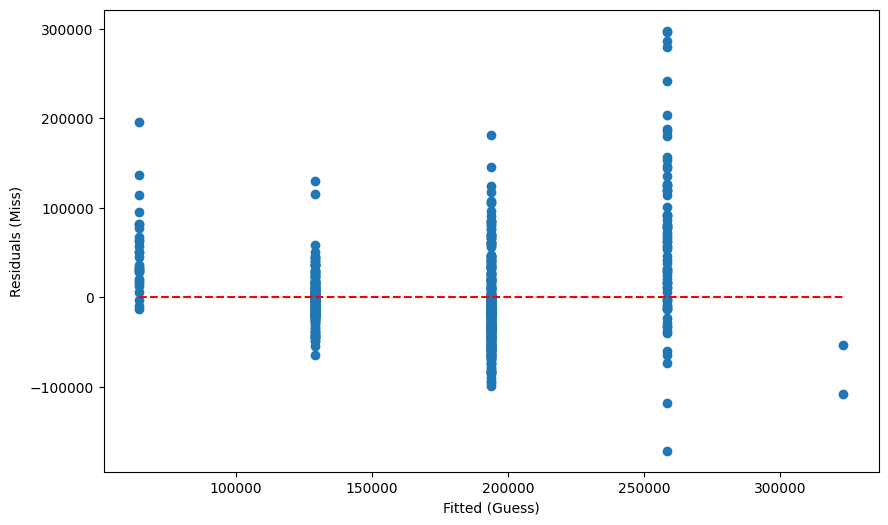

In [35]:
# Residuals vs Fitted (Predicted) Values - Constant variance

plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;



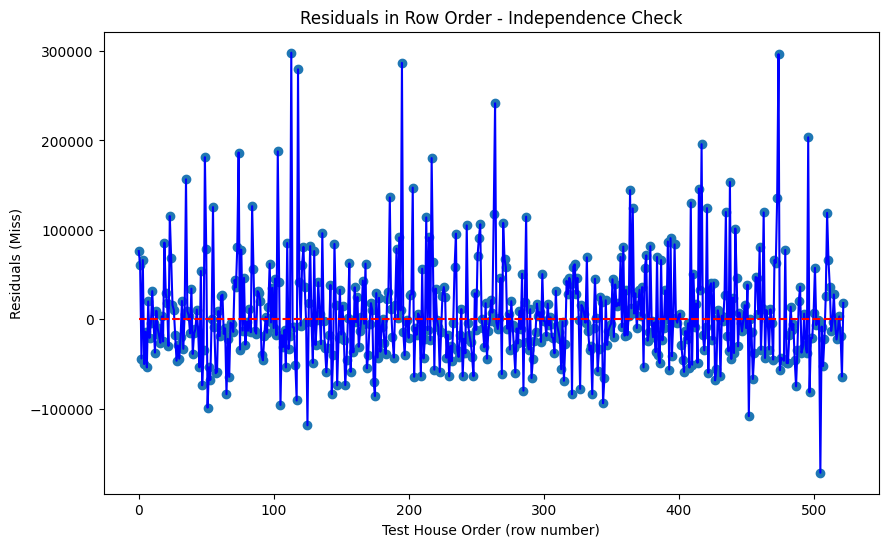

In [36]:
# Residuals vs Time - checks indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

# (does one miss tell you anything about the next miss? It shouldn't.)
# Across = house's row number (0, 1, 2...). Up = miss. Blue line connects them in order.
# Good = random zigzag around 0. Bad = waves, trends, or long runs on one side.
# My result: random zigzag, no pattern -> OK.
# Spikes go higher up than down = same right skew as before.
# Caveat: rows were shuffled by train_test_split, so "Time" is just random order.
# This check can't really fail here. Sorting by sale date would make it meaningful.

### Summary of Results
- **Model:** Linear Regression, one feature chosen by feature selection.
- **Feature selection:** ranked all 11 float features by correlation with SalePrice. Chose the #1 feature, Garage Cars (0.65).
- **Scores:**
  - Test RMSE: \$58,846
  - 10-fold CV RMSE: \$59,542
  - Guessing the average misses by \$79,225
- **Compared to earlier passes (CV RMSE):**
  - Pass 04, Lot Frontage (ranked #7): \$73,679
  - Pass 07, Mas Vnr Area (ranked #5): \$67,440
  - Pass 08, Garage Cars (ranked #1): \$59,542
  - Better-ranked feature → better model. The feature selection ranking predicted the results.
- **What the model learned:** each garage space adds about \$64,765. A house with no garage is guessed at \$64,245.
- **Limitation:** Garage Cars is only 0–5, so the model can only make about 6 different guesses. Houses with the same garage size get the same price, no matter how big or nice they are.
- **Residual analysis:**
  - QQ plot: right end curves up → misses are still right-skewed.
  - Residuals vs fitted: dots stack in columns, one per garage size.
  - Independence: random zigzag, OK.
- **Takeaway:** the best single feature cut the miss from \$74k to \$60k. But one feature can't describe a whole house.
- **Next:** Ridge Regression on the float features (Pass 09).